# LAB01 - **Creación de un agente conversacional con RAG en la nube**

In [1]:
from google.colab import drive
from IPython.display import Image, display
DRIVE_PATH = '/content/drive/MyDrive/Universidad/UNIR/Asignaturas/Herramientas IA nube/Notebooks/repo'
drive.mount('/content/drive')

Mounted at /content/drive


## 01.01 - **Descripción del problema**

Vamos a crear un **asistente basado en IA** para agentes comerciales de un **centro de atención al cliente.**

Los requisitos funcionales del asistente son los siguientes:
- Obtener rápidamente la información que necesitan a partir de la pregunta del cliente
- Conocer el **documento de referencia** del que se ha obtenido la respuesta
- **Retrieval-Augmented Generation (RAG)**
- Información **actualizada**, no dependiente de los datos de entrenamiento
- Consideración del **contexto** de la conversación con el cliente para proporcionar respuestas o sugerencias coherentes y precisas
- Creación de **recursos en Google Cloud** para simplificar el proceso de creación del asistente

## 01.02 - **Enlaces al laboratorio**

Para tener acceso al laboratorio en un entorno real de Google Cloud vamos a utilizar **Google Skills**.\
https://www.skills.google

Sólo tenéis que autenticaros con vuestra cuenta personal de Google, seleccionar **Subscriptions** y elegir la suscripción **No cost**.\
De esta forma tenéis **35 créditos** gratis cada mes para realizar laboratorios.

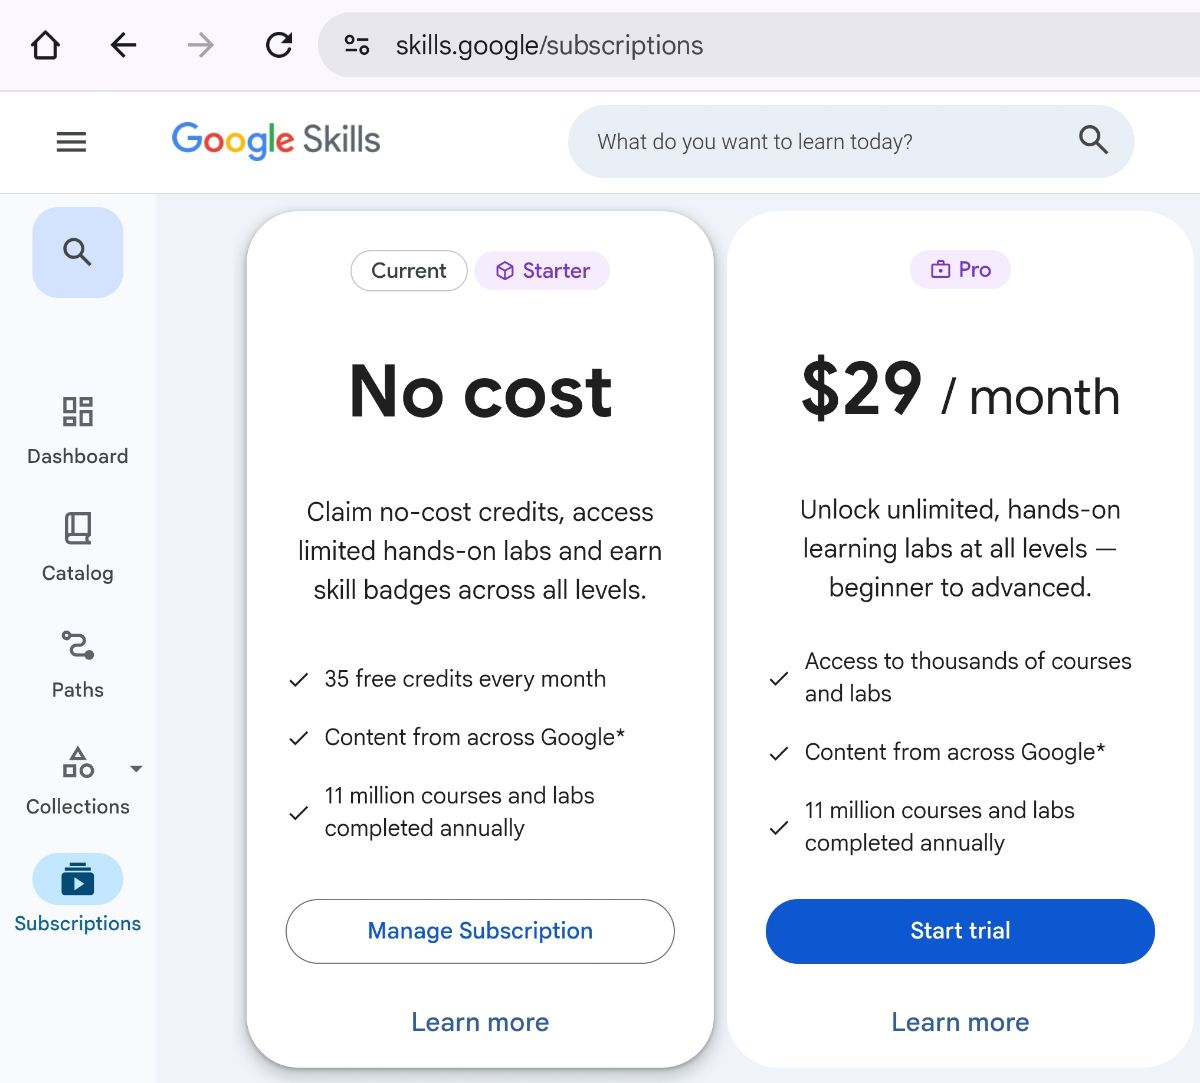

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-skills.jpg', width=350))

El enlace al laboratorio es el siguiente:\
https://www.skills.google/focuses/95398?catalog_rank=%7B"rank"%3A1%2C"num_filters"%3A0%2C"has_search"%3Atrue%7D&parent=catalog&search_id=57770497

Como alternativa podéis utilizar el siguiente guión de **CodeLabs**, que plantea el mismo escenario.
https://codelabs.developers.google.com/devsite/codelabs/building-ai-agents-vertexai#0

Sin embargo, el guión de este *notebook* se basa en los pasos que describe **Google Skills**.

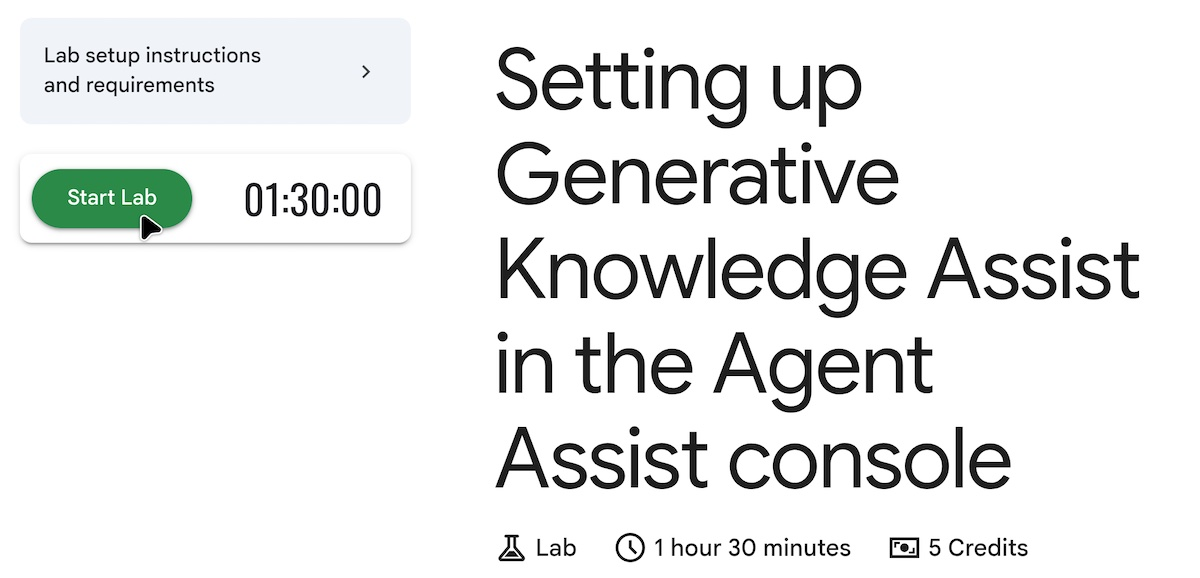

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-01.jpg', width=350))

## 01.03 - **Arranque del laboratorio**

Para iniciar el laboratorio ejecutamos los siguientes pasos:
- Inicio de sesión en **Google Skills**
- Elección del laboratorio
- Click en **Start lab**
- Click en **Open Google Cloud console** (importante, abrir en ventana de incógnito)
- Utilizar las credenciales facilitadas por **Google Skills**, no las personales



## 01.04 - **Preparación del entorno**

Después de la autenticación con las credenciales de estudiante de **Google Skills**, accedemos al **Dashboard** del proyecto de Google Cloud en el que vamos a trabajar (prefijo **qwiklabs**).

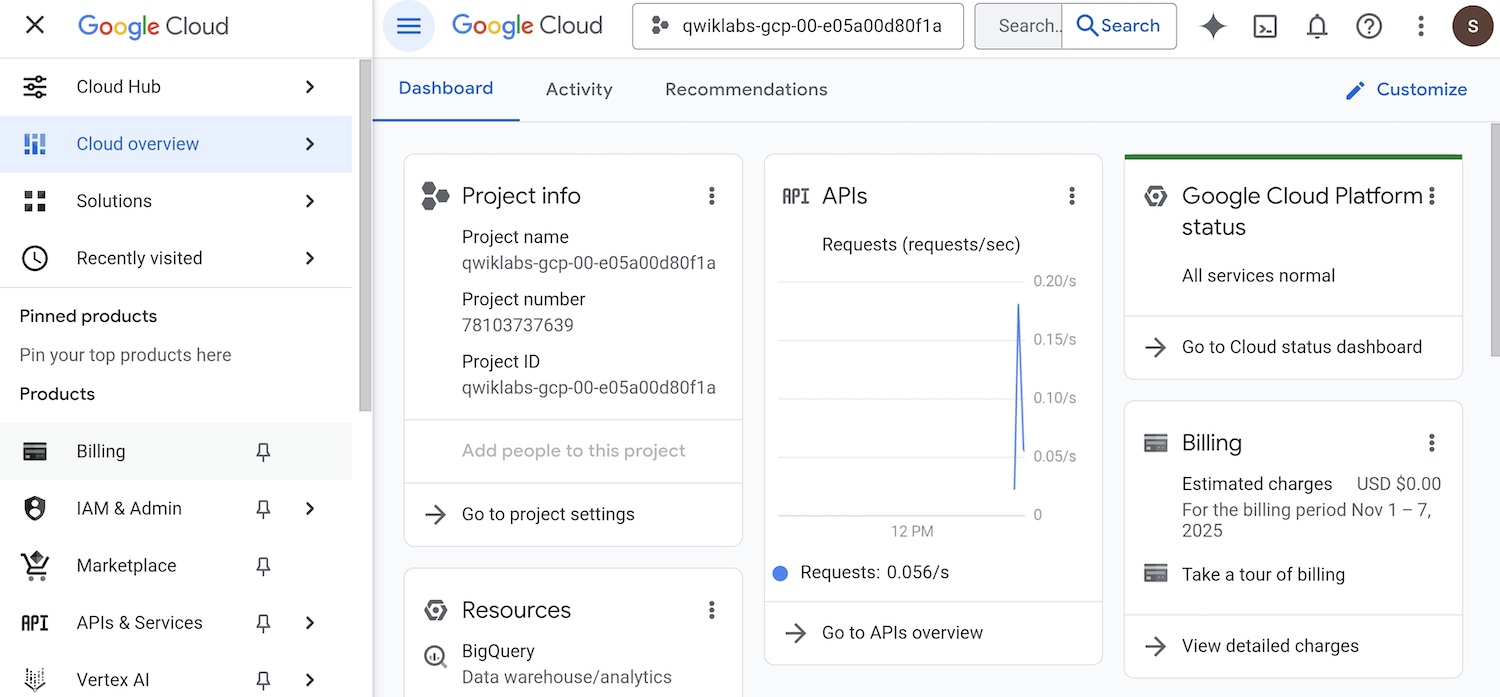

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-02.jpg', width=600))

El proyecto ha sido previamente creado por Google Skills.\
Sin embargo, este proyecto puede convivir con otros, que almacenarán sus propios recursos de forma independiente al nuestro.\
Hacemos *click* en el nombre del proyecto para comprobarlo.\
Nos aparece la lista de proyectos.

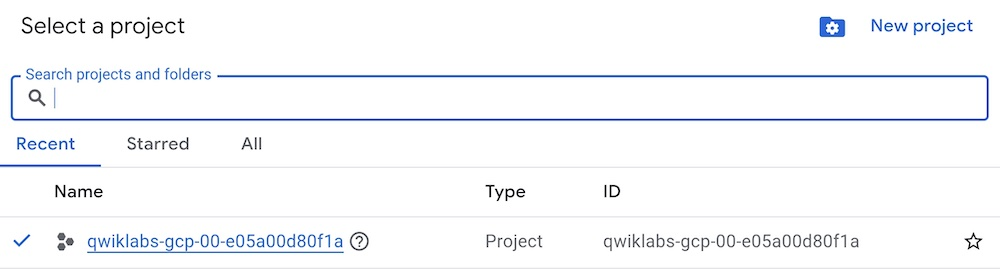

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-03.jpg', width=450))

En la lista, al hacer *click* en el nombre de nuestro proyecto aterrizamos en la página principal.\
Desde aquí, podemos regresar al cuadro de mando que vimos al principio haciendo *click* en **Dashboard**.

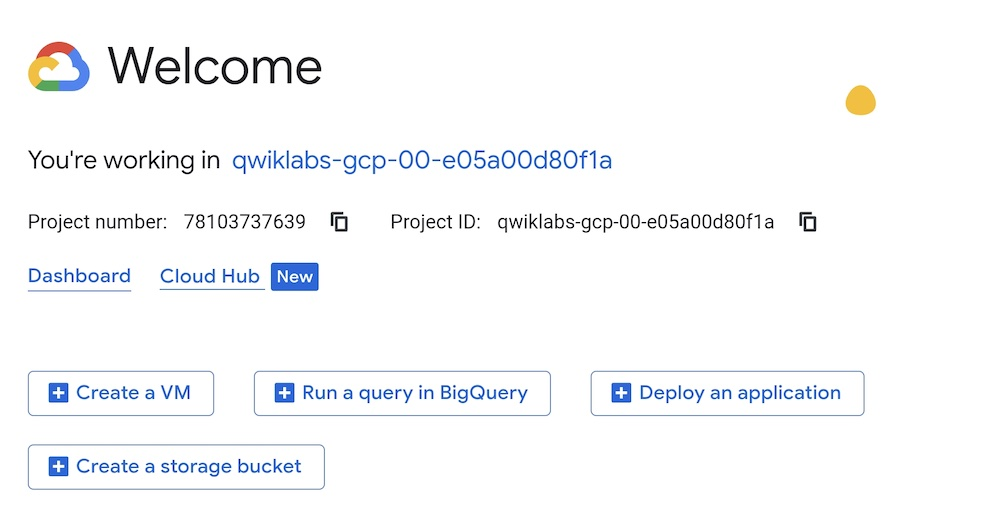

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-04.jpg', width=350))

Desde la lista de proyectos podemos hacer *click* en **New project** para crear un nuevo proyecto.\
Con esto hemos repasado la dinámica de selección y creación de proyectos, pilar clave de organización de recursos en Google Cloud.

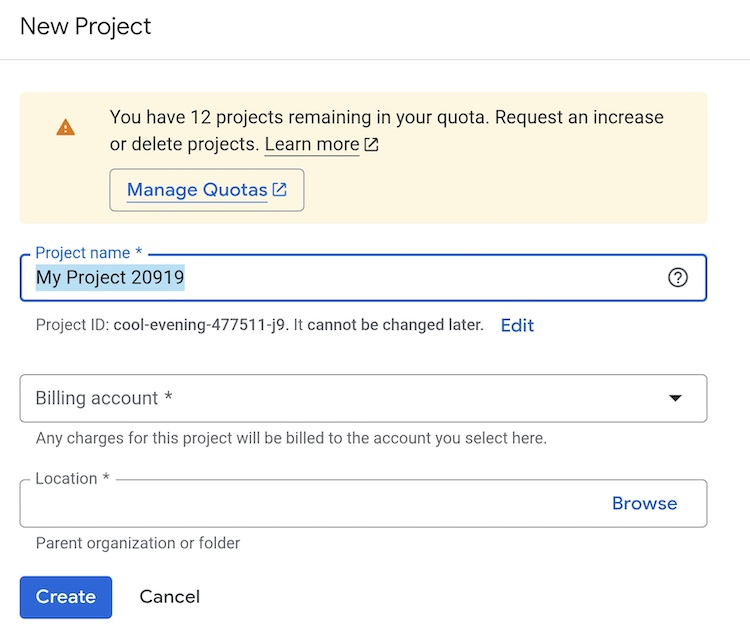

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-05.jpg', width=350))

El siguiente paso es activar **Cloud Shell**, para poder lanzar los comandos de **gcloud** que necesitemos a lo largo del ejercicio.

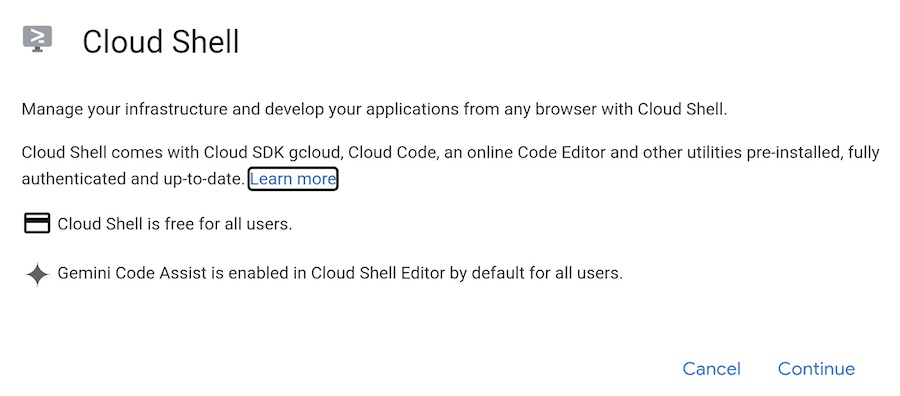

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-06.jpg', width=400))

Desde **Cloud Shell** es posible verificar que estamos usando la cuenta correcta.\
Para ello usamos el siguiente comando:
```
gcloud auth list
```

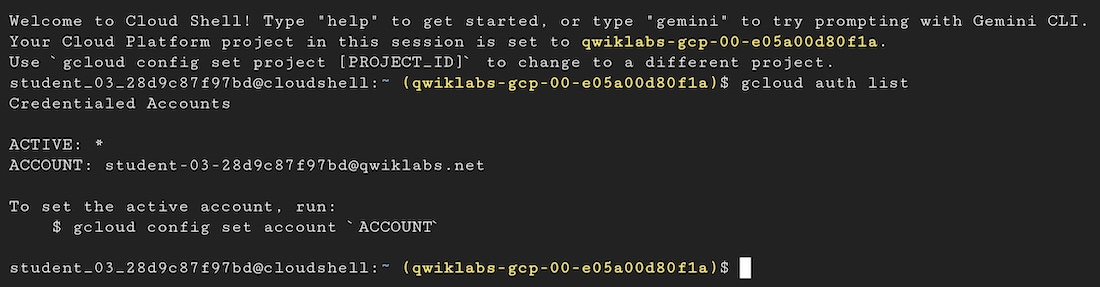

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-07.jpg', width=600))

También podemos verificar el proyecto con el que estamos trabajando actualmente.\
Para ello usamos el siguiente comando:
```
gcloud config list project
```

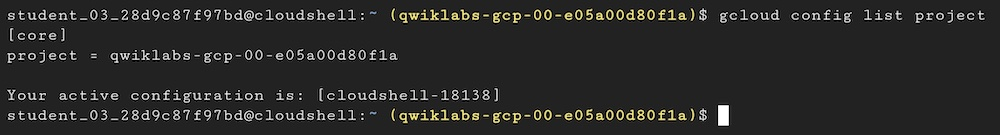

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-08.jpg', width=600))

El siguiente paso es acceder a la plataforma **AI Applications** de Google Cloud, que es el entorno en el que podemos crear nuestro asistente conversacional.\
https://console.cloud.google.com/gen-app-builder/start?pli=1

**AI Applications** también se utiliza para buscadores y sistemas de recomendación.

Al acceder por primera vez, nos solicita que **activemos la API correspondiente** para poder acceder a todas las funcionalidades de la plataforma.

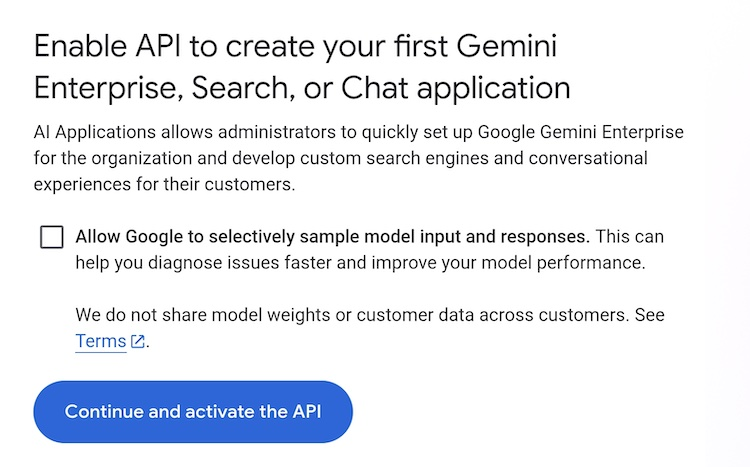

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-09.jpg', width=350))

## 01.05 - **Creación del asistente**

Por defecto, tras la activación de la API, nos aparece el *wizard* de **Create app**.\
Sin embargo, nosotros vamos a hacer *click* en **Apps** para lanzar el proceso de creación de forma manual.

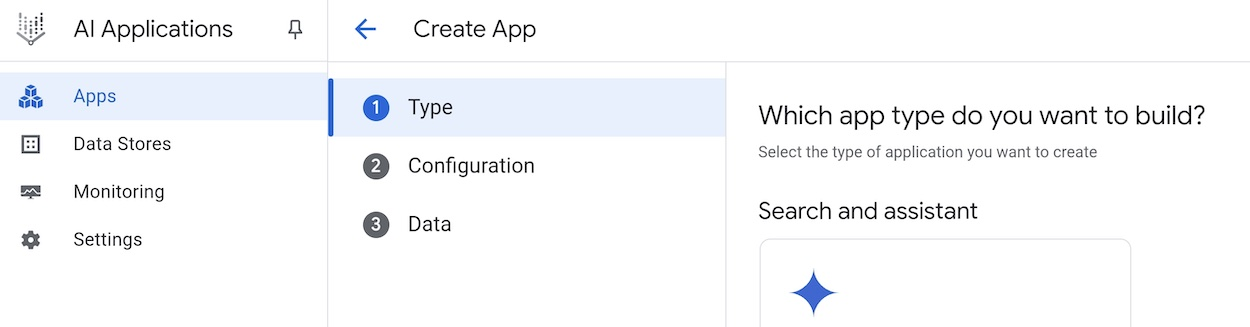

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-10.jpg', width=500))

Observamos que todavía no hay ninguna *app* creada.\
Hacemos *click* en **Create a new app**.

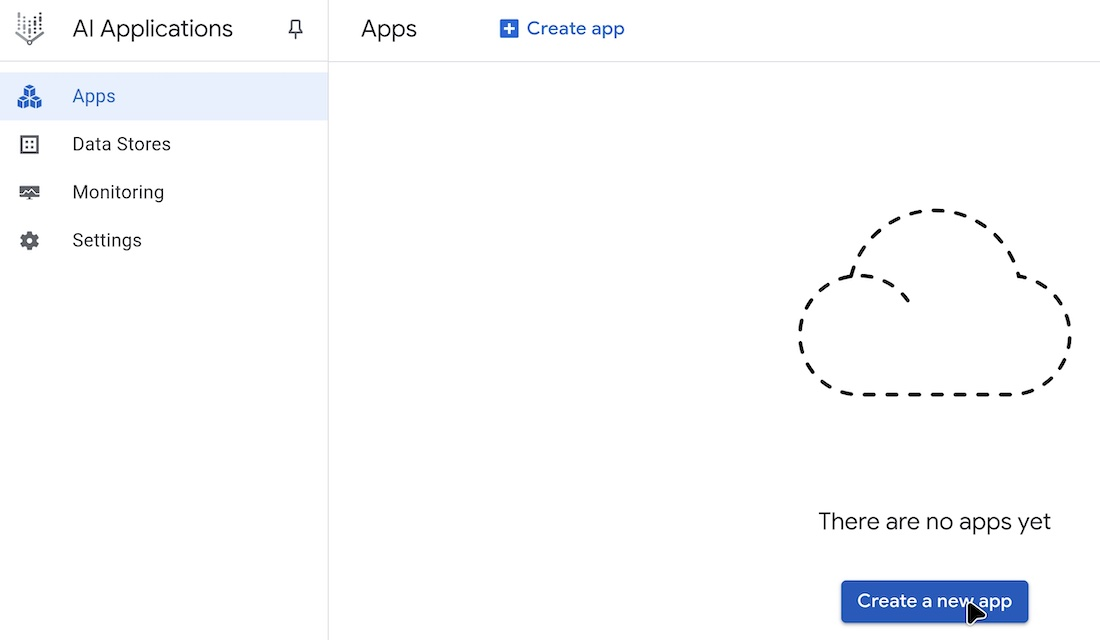

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-11.jpg', width=450))

De esta forma lanzamos de nuevo el *wizard* de creación de *apps*.\
El primer paso es elegir el tipo de *app* que queremos crear.\
En nuestro caso tenemos que seleccionar **Chat**, puesto que se trata de un asistente conversacional sencillo, que responderá a partir de la documentación proporcionada (se denomina un **data store agent**).\
La opción de **Conversational agent** se utiliza para escenarios más complejos, en los que se tienen que definir flujos conversacionales personalizados.

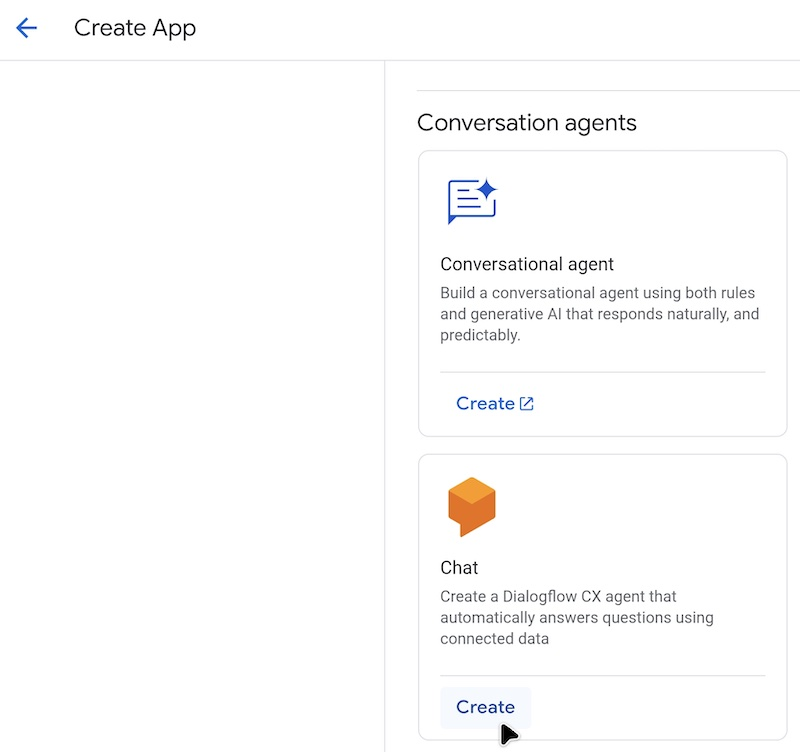

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-12.jpg', width=350))

Iniciamos la configuración del asistente.\
Indicamos el **nombre de la empresa** para la que trabaja el asistente, y el **nombre que le damos al propio asistente** para identificarlo posteriormente.

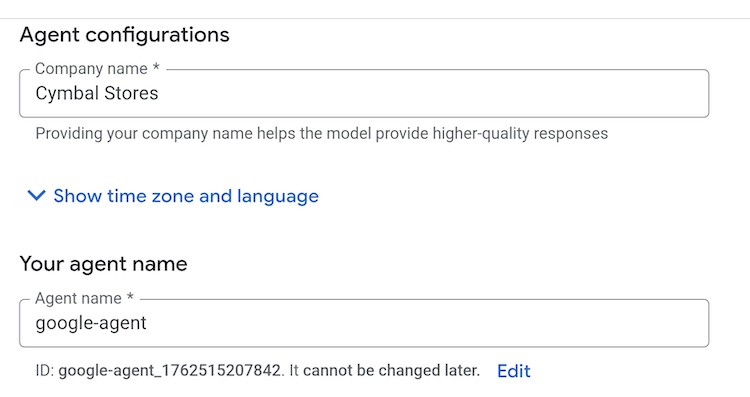

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-13.jpg', width=300))

A continuación seleccionamos la ubicación del asistente.\
Elegimos **Multi-region** para tener la máxima disponibilidad en cualquier región, a expensas de una mayor latencia para usuarios fuera de EEUU.\
La opción **global** es equivalente a **EEUU** en la jerga de Google Cloud.

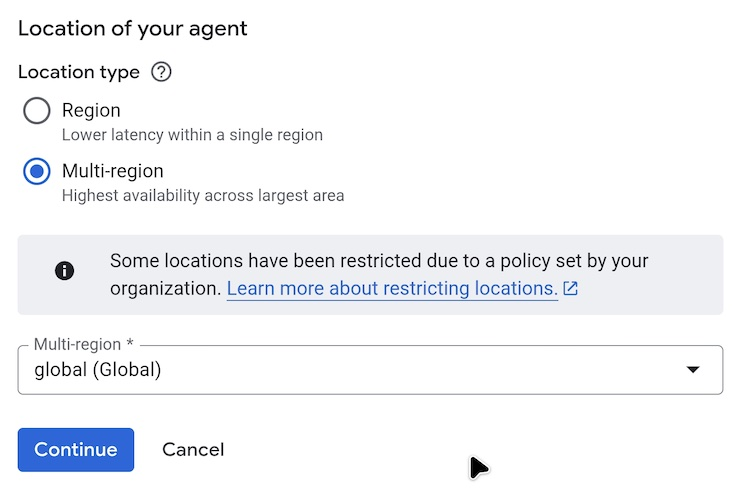

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-14.jpg', width=300))

## 01.06 - **Creación del almacén de datos**

Como nuestro asistente basará sus respuestas en el contenido de documentos que le proporcionemos, tenemos que crear un *data store*.\
Hacemos *click* en **Create Data Store**.

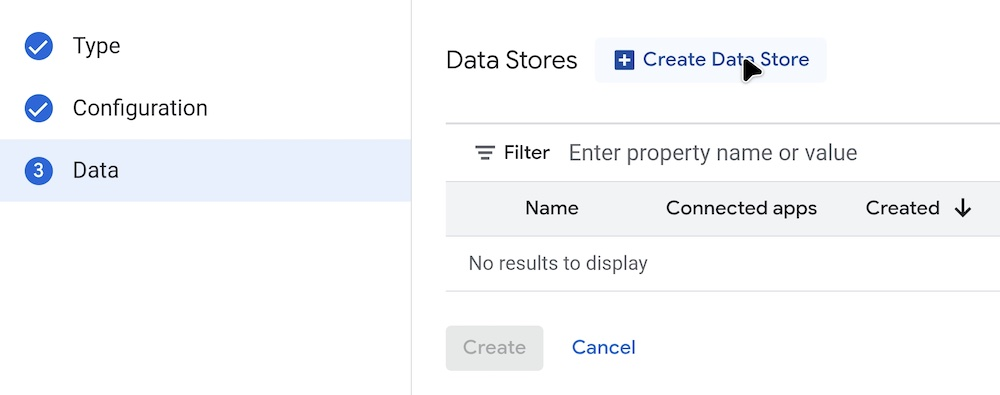

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-15.jpg', width=350))

Podemos incorporar como origen de datos para el asistente un **sitio web** o un *bucket* de **Cloud Storage**.\
En este caso optamos por la segunda opción, porque Google Cloud nos proporciona un *bucket* con documentos que podemos utilizar para el ejercicio.

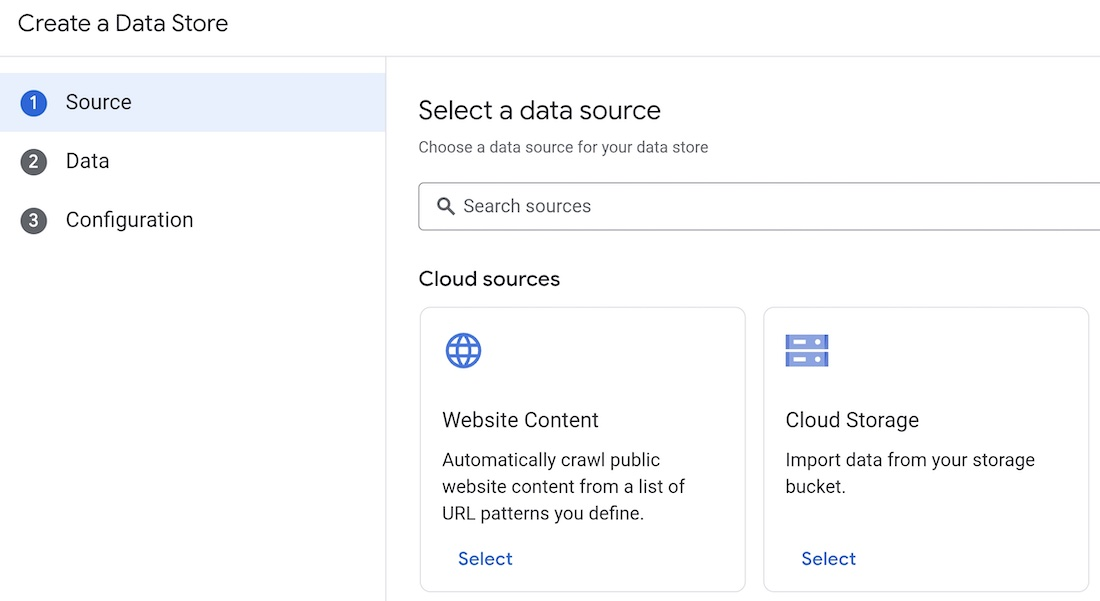

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-16.jpg', width=350))

La información que vamos a proporcionarle al asistente está en formato HTML, por lo que tenemos que seleccionar la opción **Unstructured documents**.

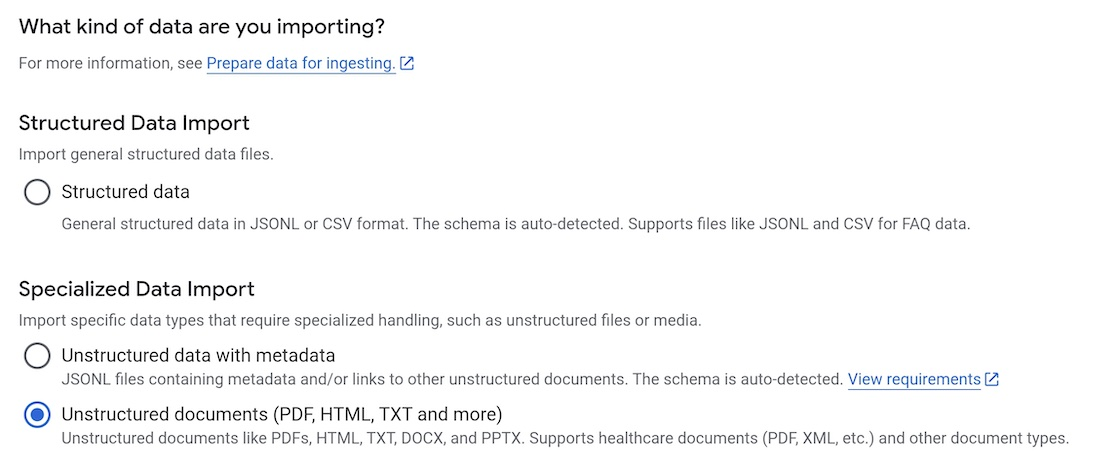

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-17.jpg', width=450))

A continuación indicamos la ruta completa del *bucket* de **Cloud Storage** que almacena los documentos.
```
cloud-samples-data/dialogflow-cx/google-store
```

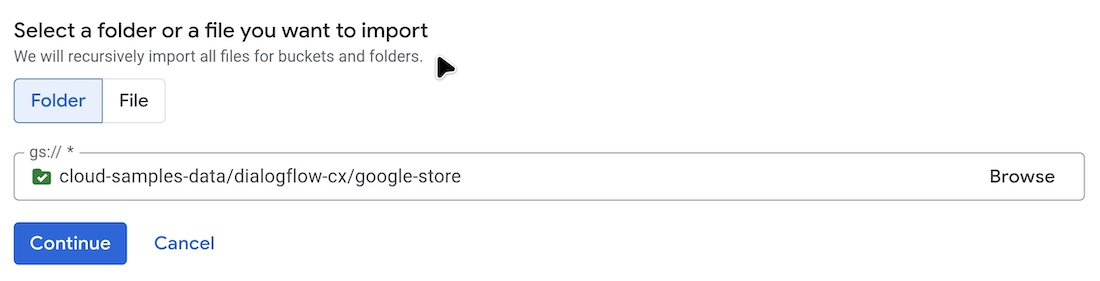

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-18.jpg', width=450))

Asignamos el nombre **google-store** a este *data store*, y hacemos *click* en **Create**.\
A continuación seleccionamos el *data store* recién creado para asignárselo al asistente, y hacemos *click* en **Create** para completar el proceso.

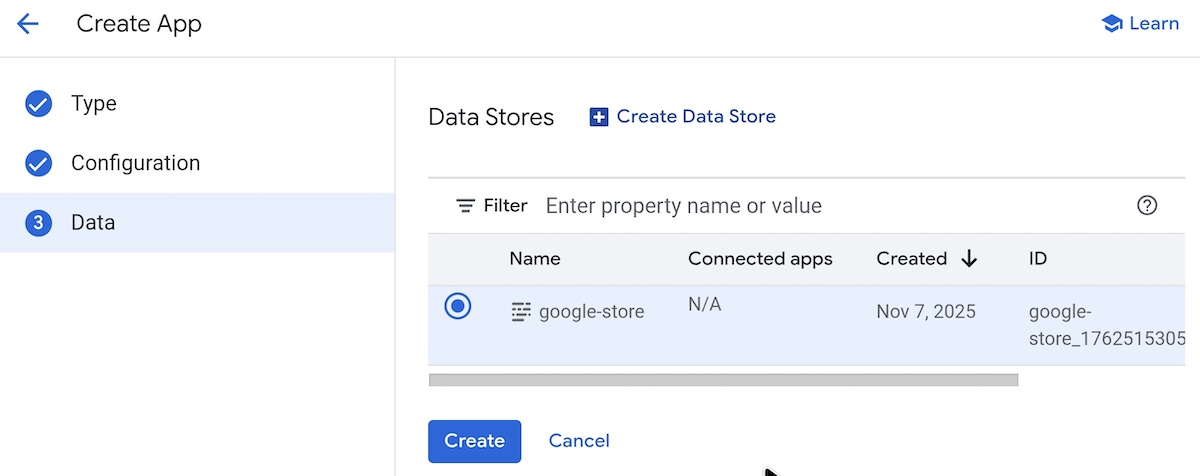

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-19.jpg', width=500))

Si hacemos *click* en **Data Stores**, observamos que nos aparece también aquí el *data store*.\
Eventualmente podríamos usarlo con otros asistentes conversacionales que requieran la misma información que el nuestro.

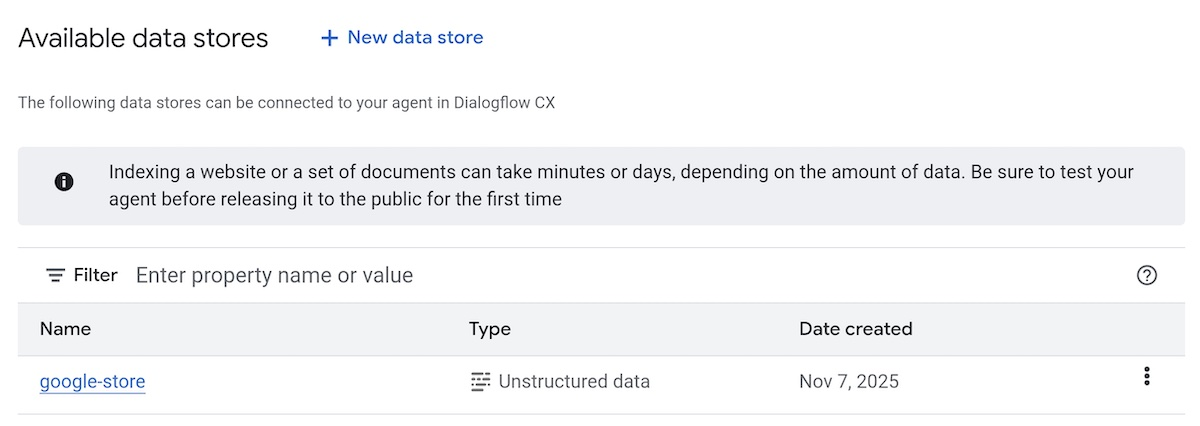

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-20.jpg', width=500))

Hacemos *click* en el *data store* para acceder a la página que nos muestra sus detalles.\
Lo que nos interesa en este momento es hacer *click* en **Activity**, para comprobar que el proceso de indexación de documentos está en marcha.\
**IMPORTANTE:** el proceso de indexación puede necesitar hasta 20 minutos para completarse.

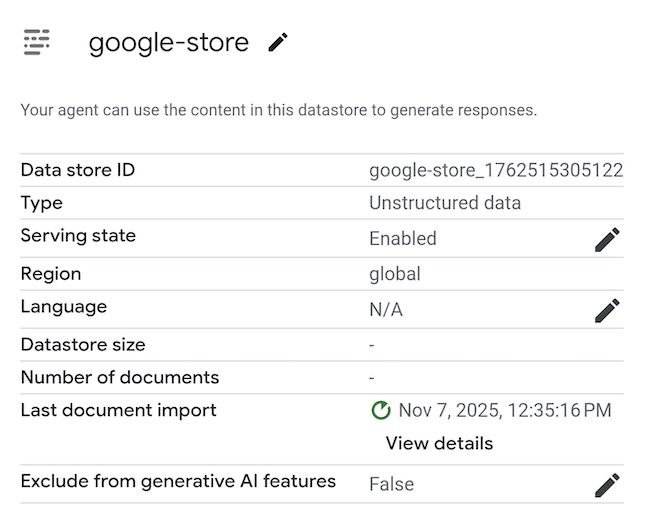

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-21.jpg', width=250))

Comprobamos que efectivamente el estado es **Import in progress**.

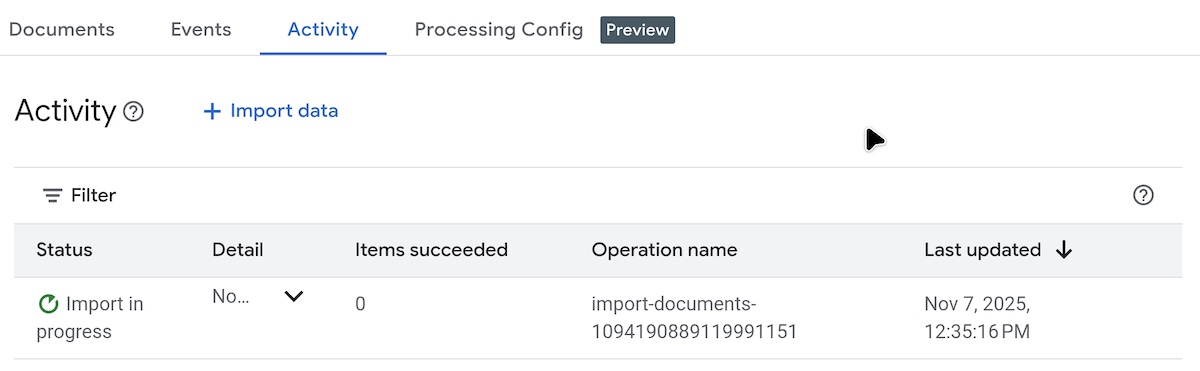

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-22.jpg', width=500))

## 01.07 - **Uso del simulador para pruebas**

Mientras tanto, si hacemos *click* en **Apps** vemos que ahora aparece nuestro asistente en la lista.

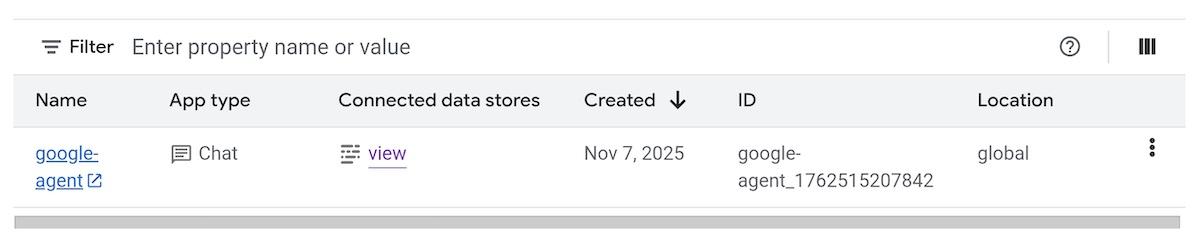

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-23.jpg', width=500))

Al hacer *click* en el nombre del asistente se nos redirige a la consola de **Conversational Agents**, desde la que podemos configurarlo y probarlo.\
Tenemos que asegurarnos de que **Toggle simulator** está activado, para ver la interfaz de usuario que emplearemos para las pruebas.

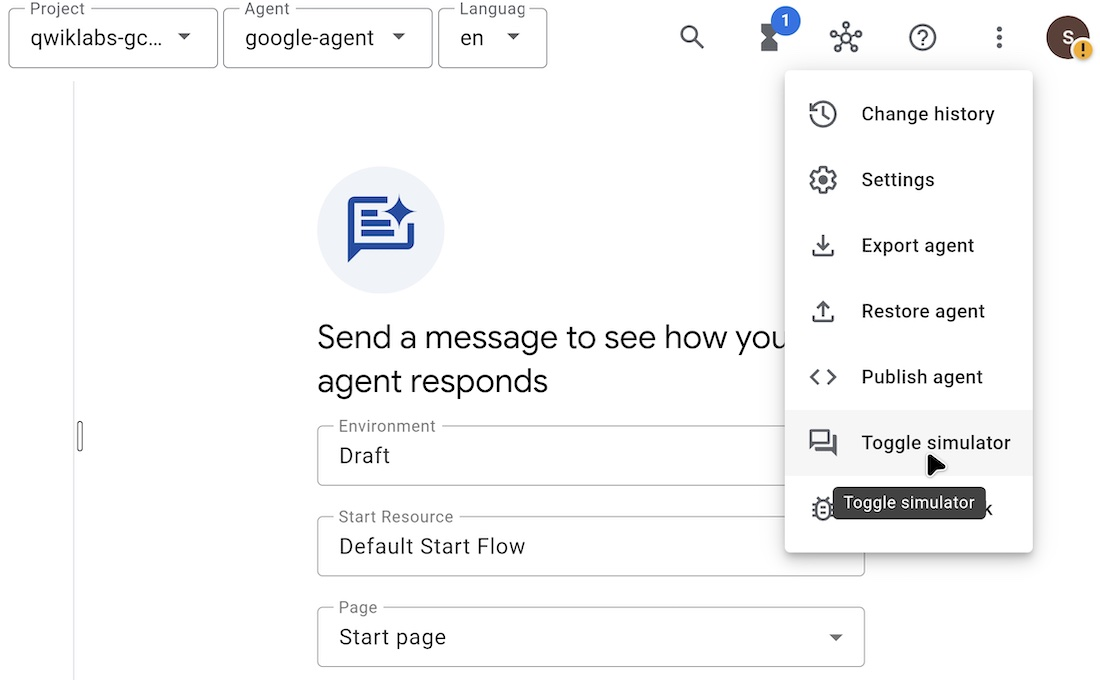

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-24.jpg', width=350))

En el simulador tenemos 3 menús despegables, correspondientes al **entorno**, el **recurso de inicio** y la **página**.

Estos conceptos están asociados a **Dialogflow CX**, la plataforma de construcción de *chatbots* de Google Cloud que hemos utilizado *sin saberlo* (a través del *wizard*) para construir el asistente.

Describimos cada uno de ellos a continuación:

**Entorno**\
Es la versión del asistente. En Dialogflow CX es posible tener múltiples versiones, tanto numeradas como por nombre.\
La versión **Draft** se refiere a la que estamos editando actualmente.

**Recurso de inicio**\
Se refiere al flujo (*flow*) del que queremos partir para la prueba. El concepto de flujo coincide con el de *topic* en Copilot Studio.\
En este caso utilizamos el flujo de inicio por defecto.\
En nuestro escenario no necesitamos ningún otro flujo porque realmente nuestro asistente va a contestar a partir del conocimiento de los ficheros HTML que le hemos aportado.

**Página**\
Se refiere a la página concreta dentro del flujo en la que se quiere iniciar la conversación. Cada flujo tiene un conjunto de páginas que representan los *estados* o *pasos* de la conversación.\
En este caso elegimos la página de inicio del flujo seleccionado.

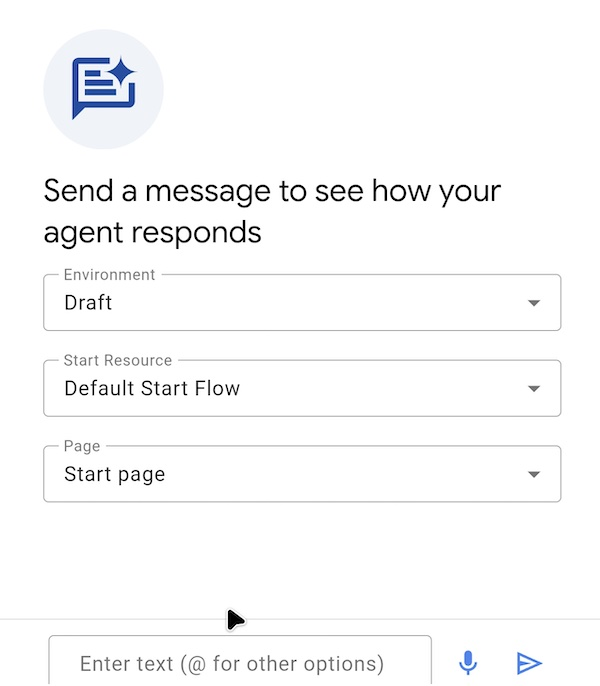

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-25.jpg', width=200))

Realizamos una prueba rápida que consiste en saludar al asistente.\
Obtenemos como respuesta el saludo por defecto configurado en el flujo **Default Start Flow**.\
Esta respuesta se desencadena después de identificar nuestro **Hello** con el *intent* **Default Welcome Intent**.

El concepto de *intent* es muy similar al de *trigger* que vimos en Copilot Studio.

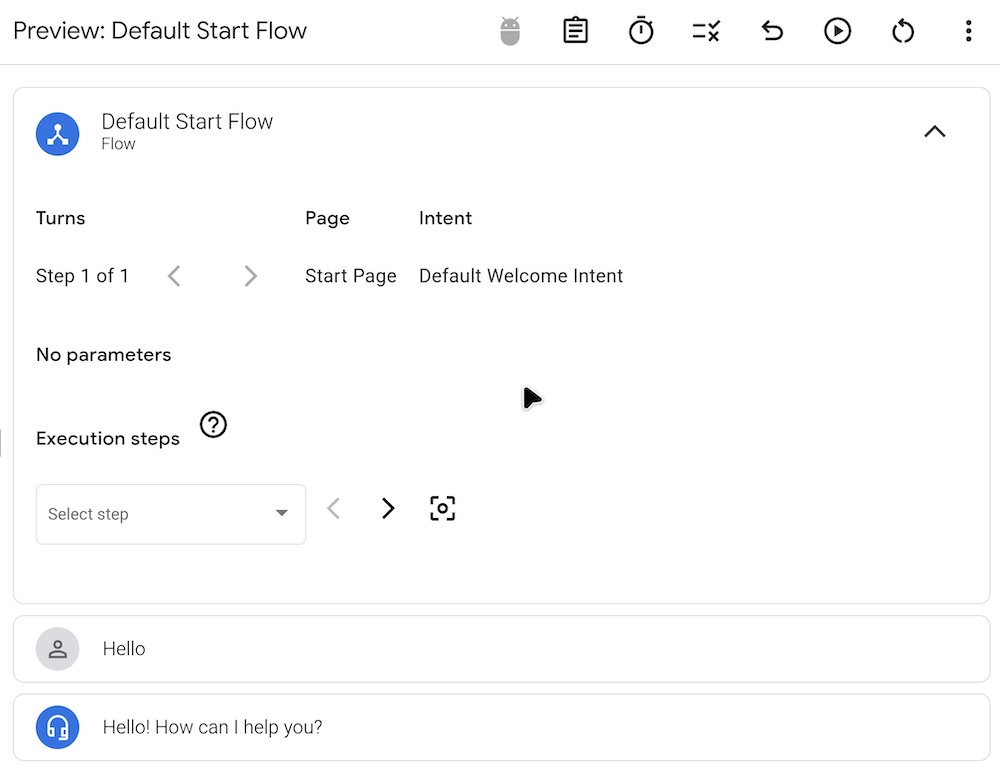

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-34.jpg', width=400))

Dentro del simulador, ahora podemos lanzar una pregunta cuya respuesta se encuentre dentro de la base de conocimiento del asistente.\
Por ejemplo:

**What are the available smartwatch brands in the Google Store?**

Observamos que el asistente aún no dispone de una respuesta porque no ha finalizado el proceso de indexación.

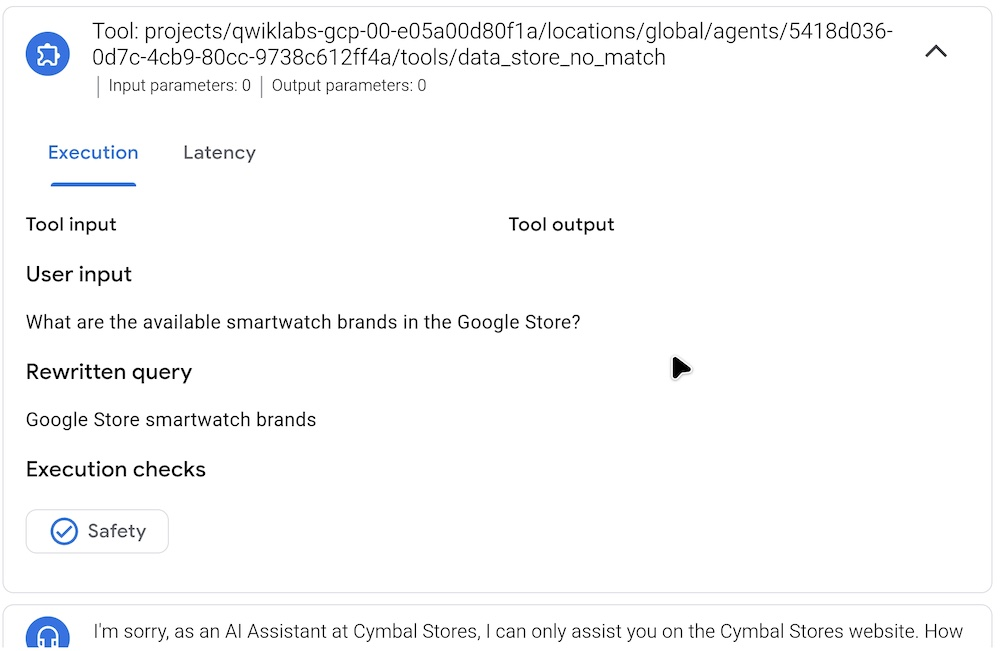

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-26.jpg', width=400))

Una vez que se ha completado el proceso de indexación, en la pestaña **Documents** del *data store* encontramos la lista de ficheros HTML que ahora forman parte del conocimiento del asistente.

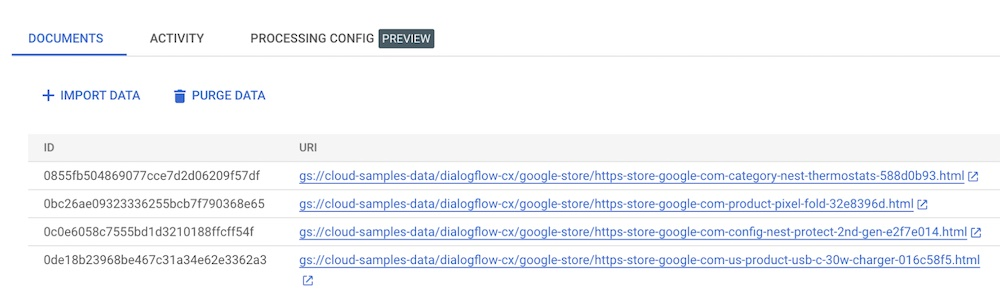

In [12]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-37.jpg', width=600))

Podemos hacer *click* en alguno de ellos para ver el tipo de contenido que almacenan.\
Por ejemplo, en la siguiente captura mostramos una de las páginas del sitio web que publicita los termostatos de Google.

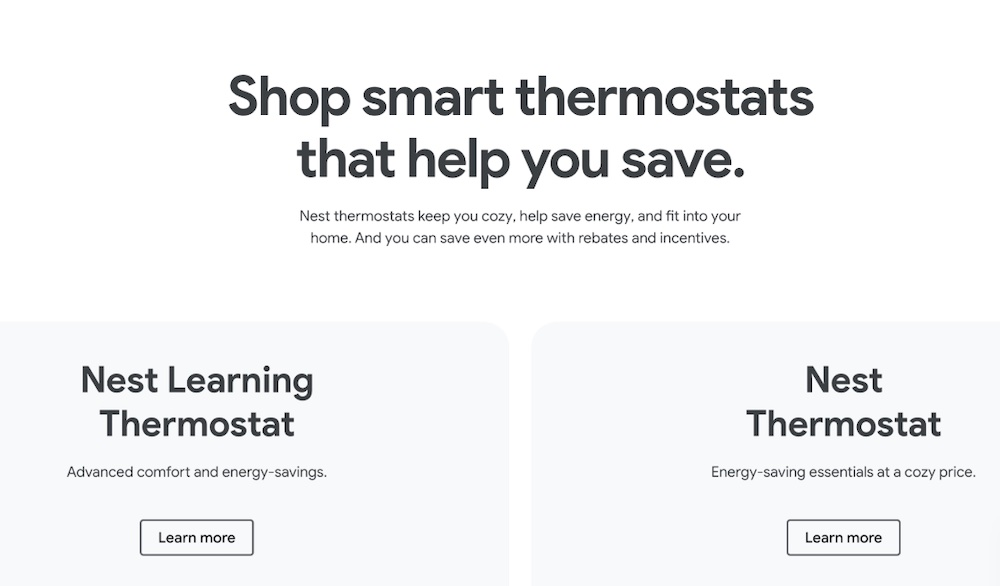

In [14]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-39.jpg', width=350))

## 01.08 - **Integración del asistente**

El objetivo de nuestro asistente es proporciona respuestas inmediatas a un agente comercial humano que está teniendo una conversación vía *chat* o telefónica con un potencial cliente.

Para este escenario, Google Cloud proporciona un entorno específico denominado **Agent Assist**, en el que el agente humano dispone de una interfaz con dos secciones: por un lado, **la conversación con el cliente**, y por otro, **la conversación con el asistente**, para trasladarle las preguntas del cliente.

Podemos acceder a **Agent Assist** a través del menú lateral de la consola **Conversational Agents**.

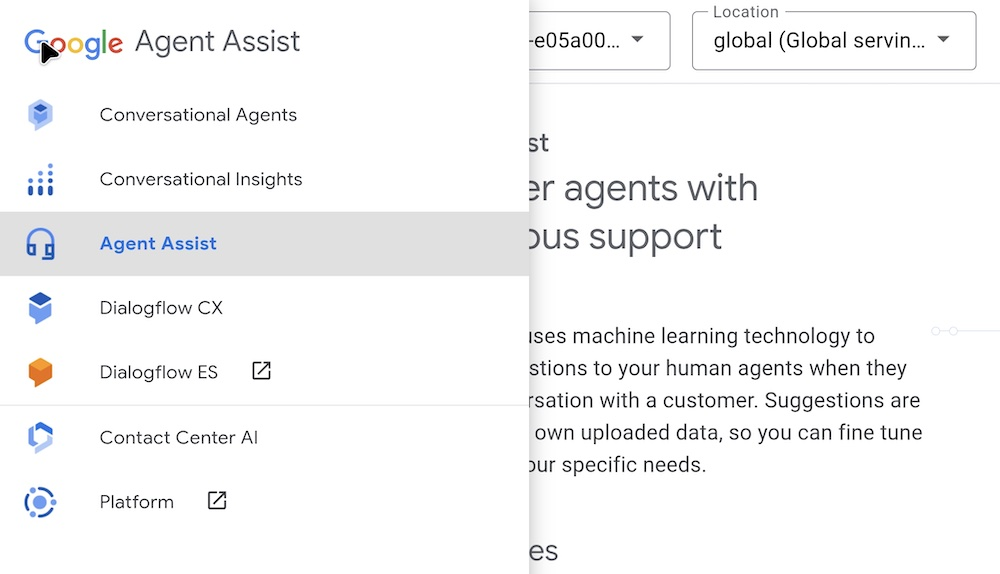

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-27.jpg', width=400))

El siguiente paso es hacer *click* en **Conversational profiles**, y a continuación en el botón **Create new**.

Los perfiles de conversación son configuraciones de alto nivel que definen cómo debe comportarse y qué herramientas debe utilizar el entorno que dará soporte al agente humano.

Este entorno está basado en el asistente (*agent*) que hemos creado en pasos previos.

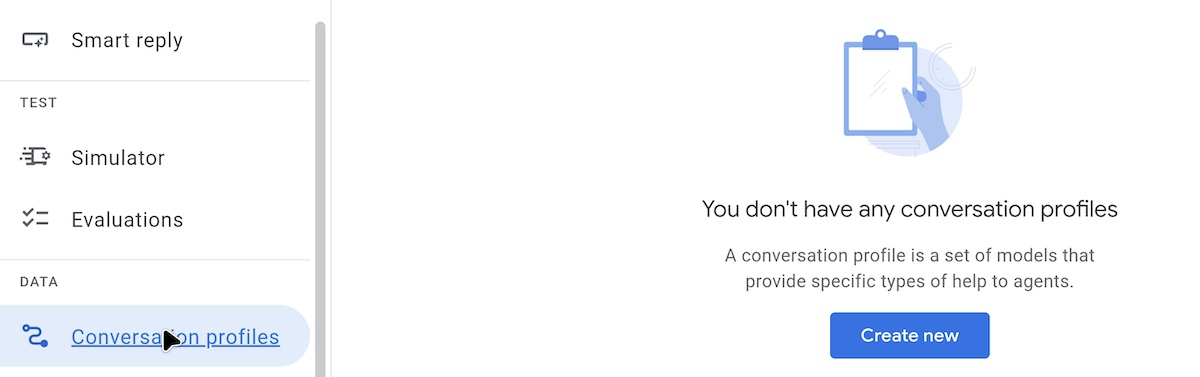

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-28.jpg', width=450))

Seleccionamos un **nombre** y un **idioma** para el perfil de conversación.

La configuración de idioma determina en qué idioma espera recibir las peticiones el asistente basado en **Dialogflow CX** que vamos a seleccionar en el siguiente paso.

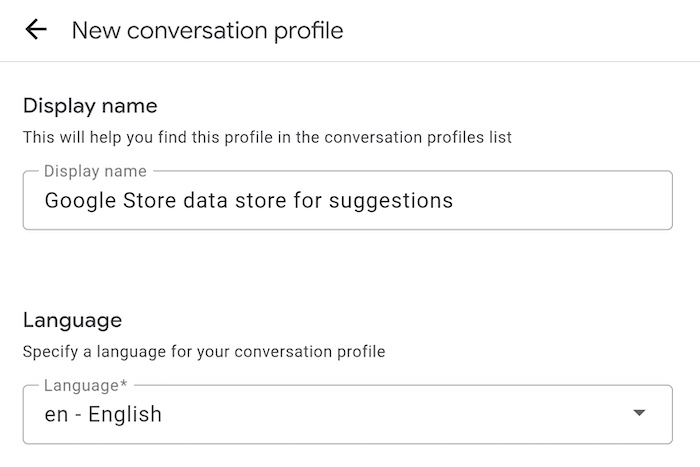

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-29.jpg', width=250))

En el siguiente paso seleccionamos el asistente creado en pasos previos: **google-agent**.\
Para ello, tenemos que marcar la casilla **Generative knowledge assist**.\
Esto significa que el entorno utilizará un asistente de Dialogflow CX **conectado a un *data-store*** para dar soporte al agente humano.

Además, tenemos que activar la opción **Enable conversation augmented query** para asegurarnos de que el asistente emplea el **contexto** de la conversación y no sólo la petición actual para generar una respuesta.

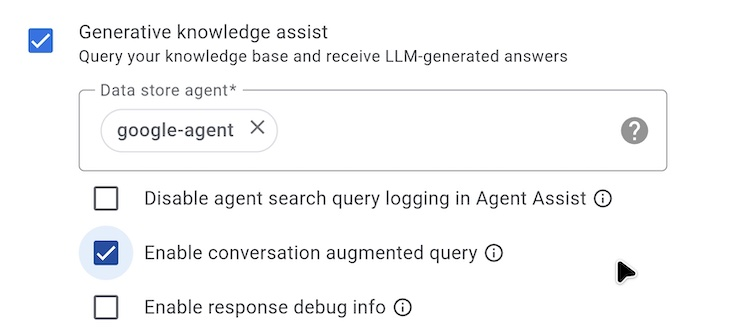

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-30.jpg', width=300))

Una vez terminada la configuración, el perfil conversacional aparece en la lista de **Conversation profiles**.

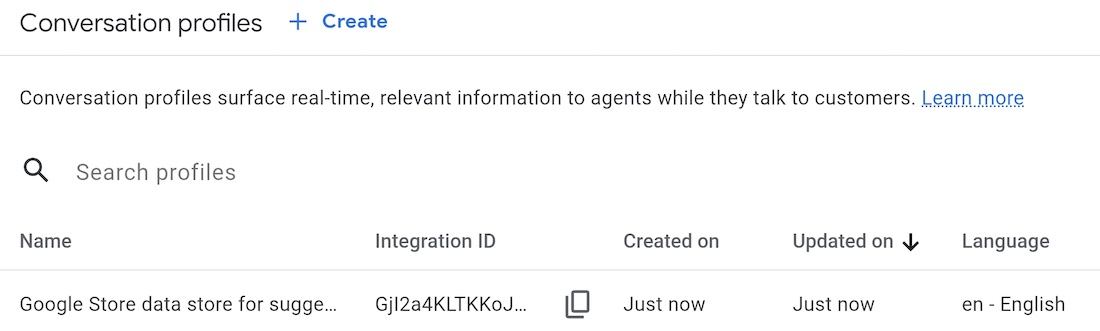

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-31.jpg', width=425))

## 01.09 - **Pruebas de la solución**

Finalmente, podemos probar nuestra solución basada en **Agent Assist**.\
Para ello, hacemos *click* en **Try it out** para el perfil conversacional que acabamos de crear.

Observamos que se muestran las dos secciones: una con la conversación que tenemos con el cliente (simulada), y otra con la conversación del agente humano con el asistente.

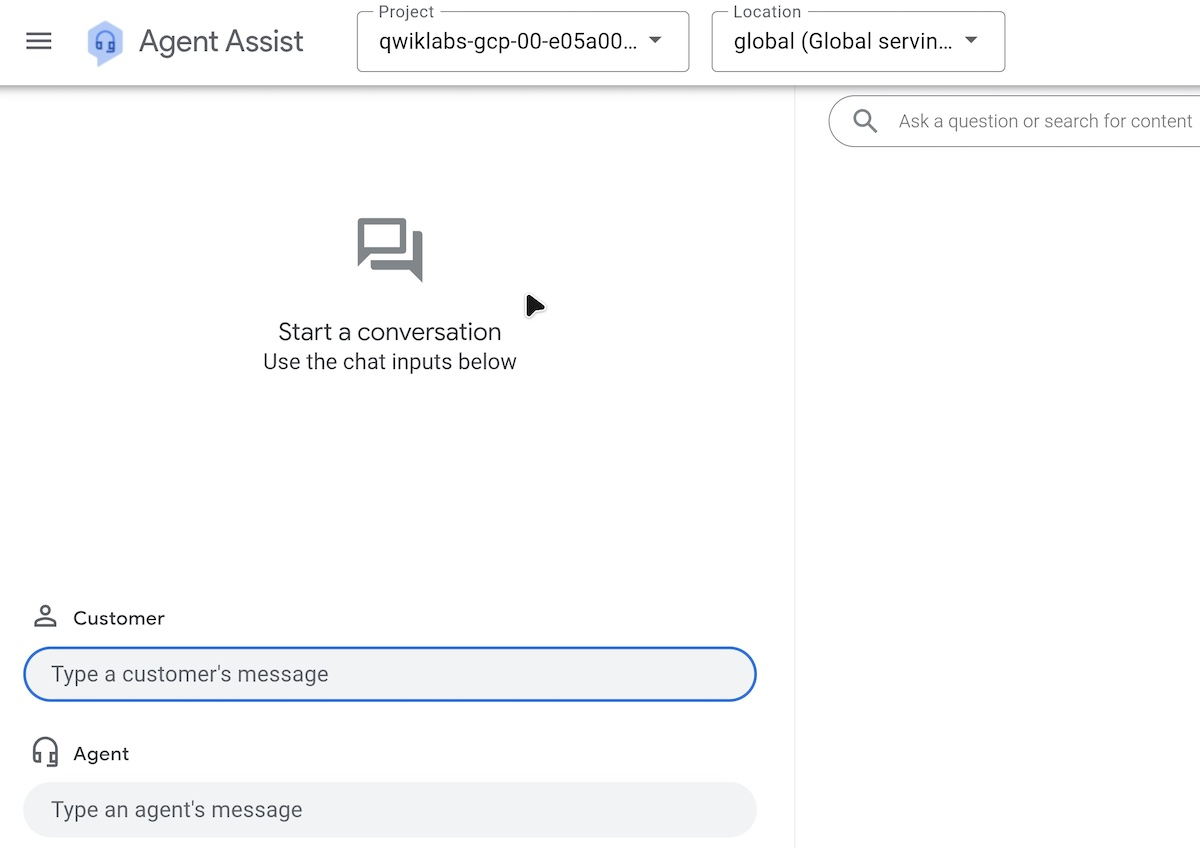

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-32.jpg', width=450))

Repetimos desde el entorno de **Agent Assist** la consulta que habíamos lanzado desde el simulador en secciones previas:

**What are the available smartwatch brands in the Google Store?**

Observamos que ahora sí se proporciona la respuesta correcta.

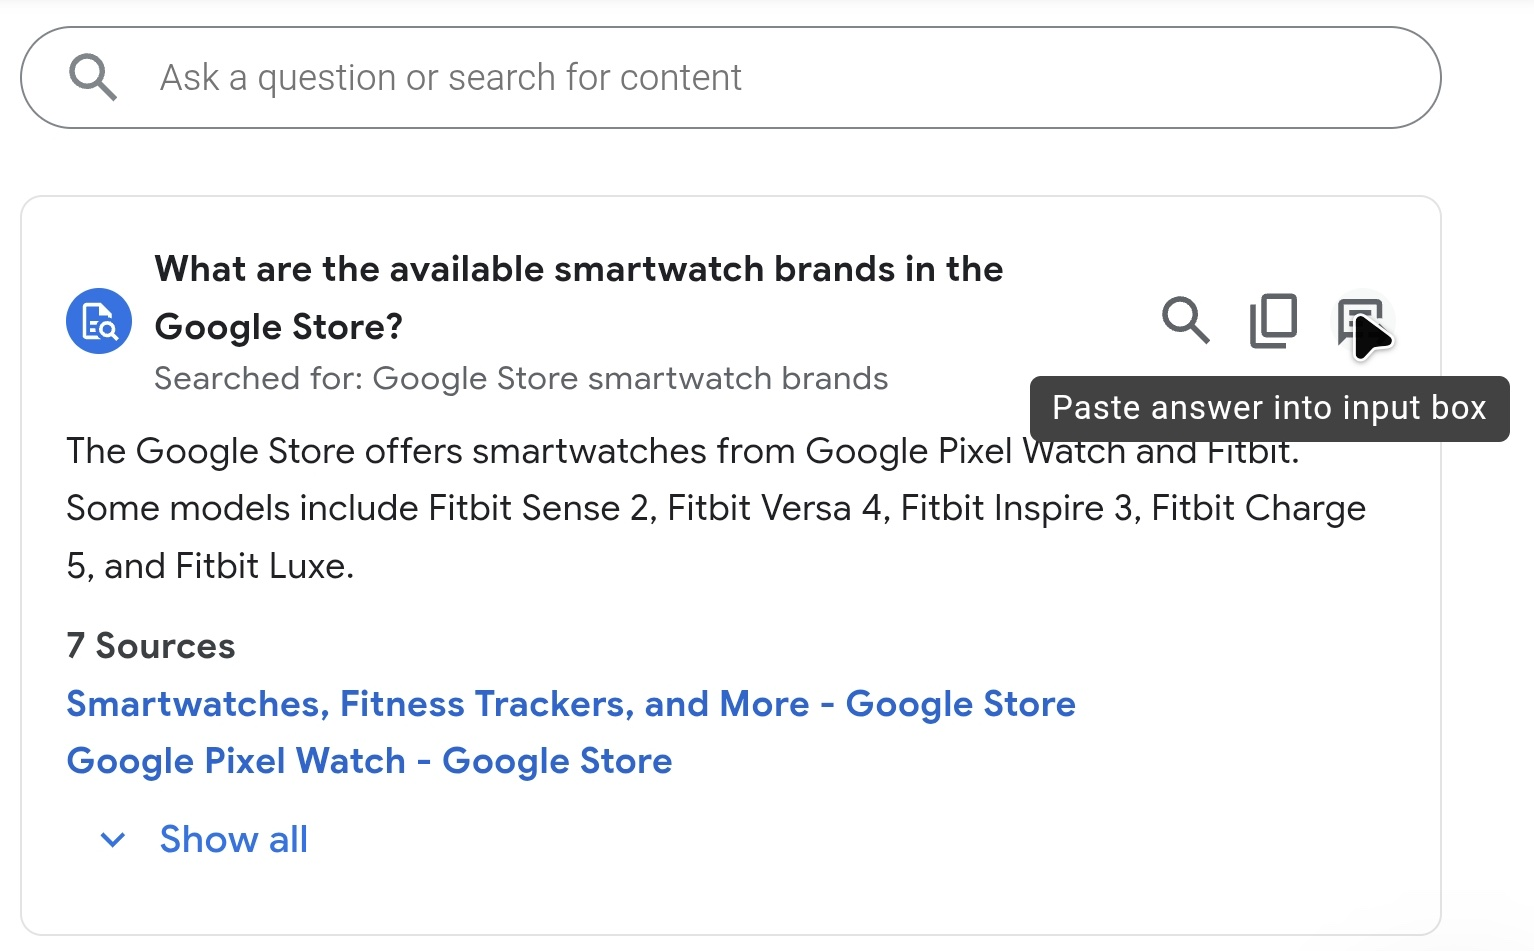

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-33.jpg', width=350))

Podemos probar también desde el simulador de **Dialogflow CX**.\
Observamos que nos proporciona información adicional, como por ejemplo el grado de **grounding** de la respuesta, es decir, en qué medida está respaldada por la base de conocimiento proporcionada.

Existen otros tipos de *grounding* que consultaremos en la documentación técnica un poco más adelante.

En este ejemplo es **Very high**.

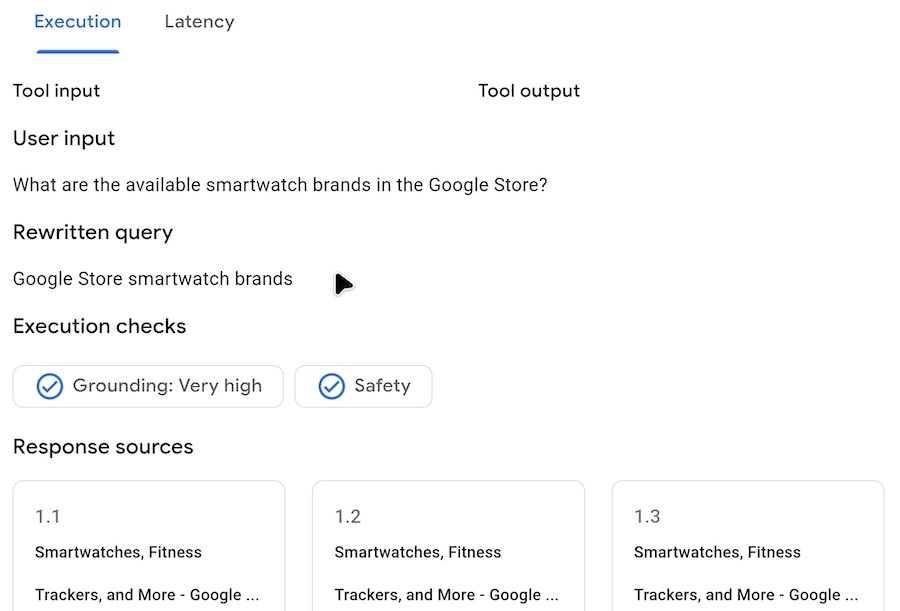

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-35.jpg', width=350))

También podemos consultar las diferentes mediciones de latencia:
- Reeescritura de la *query* original, de manera que esté optimizada para una respuesta precisa (lo hemos visto en **Agent service**).
- Búsqueda en la base de datos de documentos indexados (*vector store*).
- Resumen o construcción de la respuesta a partir de los fragmentos devueltos.
- Comprobaciones de seguridad para determinar que la respuesta no es inadecuado o tiene contenido peligroso (lo hemos visto en **Content Safety**).

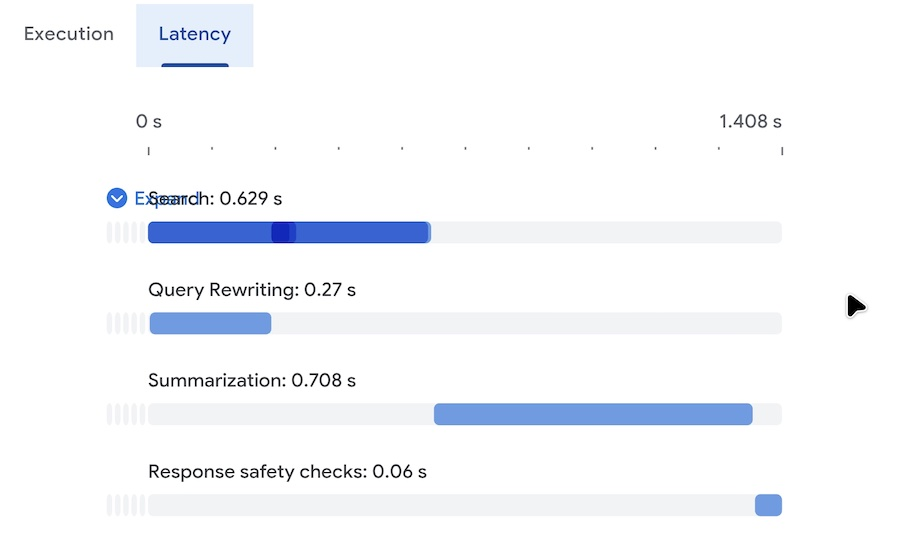

In [ ]:
display(Image(filename=DRIVE_PATH + '/images/lab01/lab01-36.jpg', width=350))

## 01.10 - **Puesta en producción de la solución**

Para la puesta en producción de la solución se deben ejecutar los siguientes pasos:
- Generar un entorno (versión) de producción del asistente basado en Dialogflow CX que hemos creado. Tened en cuenta que en el ejercicio utilizábamos la versión o entorno **Draft**.
- Asegurarnos de que el **Conversational profile** apunta a la versión de producción del agente, no a **Draft**.
- Utilizar este perfil conversacional en las llamadas a la API de Google Cloud desde el entorno en el que se integrará la solución.

https://docs.cloud.google.com/agent-assist/docs/generative-knowledge-assist

El formato de la petición HTTP es el siguiente.\
Se invoca el *endpoint* **analyzeContent** para una sesión o conversación determinada, identificada por **CONVERSATION_ID**.

El PARTICIPANT_ID identifica si el mensaje es del cliente o del agente humano. En el primer caso, se utiliza para **generar una sugerencia** de respuesta. En el segundo caso se utiliza para **incrementar el contexto de la conversación** y tenerlo en cuenta en futuras sugerencias.
```
POST https://dialogflow.googleapis.com/v2/projects/
     PROJECT_ID/conversations/CONVERSATION_ID/participants/PARTICIPANT_ID:analyzeContent
```

El formato del contenido de la petición es el siguiente.\
En **text** se especifica la consulta que plantea el cliente.
```
{
  "textInput": {
    "text": "When can I get my return refund?",
    "languageCode": "en-US"
  }
}
```

El formato de la respuesta que se recibe es el siguiente.\
En **answerText** se incluye el texto de la respuesta.\
En **generativeSource** se muestra la fuente de la que se ha extraído el contenido de la respuesta.\
En **suggestedQuery** se incluye la reescritura de la consulta original.
```
{
  "message": {
    "name": "projects/PROJECT_ID/conversations/CONVERSATION_ID/messages/MESSAGE_ID",
    "content": "When can I get my return refund?",
    "languageCode": "en-US",
    "participant": "PARTICIPANT_ID",
    "participantRole": "END_USER",
    "createTime": "2020-02-13T00:07:35.925Z"
  },
  "humanAgentSuggestionResults": [
    {
      "suggestKnowledgeAssistResponse": {
        "knowledgeAssistAnswer": {
          "suggestedQuery": {
            "queryText": "Refund processing time"
          },
          "suggestedQueryAnswer": {
            "answerText": "After your return is processed, you receive your refund in 7 days. The refund amount should be for the full value of the items returned, but doesn't include shipping & service fees.",
            "generativeSource": {
              "snippets": [
                {
                  "title": "Returns & refunds - Help",
                  "uri": "https://example.com/",
                  "text": "When the package with your return arrives at the seller's return center, it may take up to 7 additional business days to process. Check the status of your refund with the return tracking number found on your orders page."
                }
              ]
            },
          },
          "answerRecord": "projects/PROJECT_ID/answerRecords/ANSWER_RECORD_ID"
        },
      }
    }
  ]
}
```